In [1]:
from google.colab import files
uploaded = files.upload()

Saving SampleSuperstore.csv to SampleSuperstore.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("SampleSuperstore.csv")

# Display the first five rows
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (9994, 13)

Column names:
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object

In [5]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values in each column:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Number of duplicate rows:
17


In [7]:
print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

Rows before removing duplicates: 9994
Rows after removing duplicates: 9977


In [8]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


In [9]:
if 'Order Date' in df.columns:
    df['Order Date'] = pd.to_datetime(
        df['Order Date'],
        errors='coerce'
    )

print(df.dtypes)

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [10]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9977.000000,9977.000000,9977.000000,9977.000000,9977.00000
mean,55154.964117,230.148902,3.790719,0.156278,28.69013
std,32058.266816,623.721409,2.226657,0.206455,234.45784
min,1040.000000,0.444000,1.000000,0.000000,-6599.97800
25%,23223.000000,17.300000,2.000000,0.000000,1.72620
50%,55901.000000,54.816000,3.000000,0.200000,8.67100
75%,90008.000000,209.970000,5.000000,0.200000,29.37200
max,99301.000000,22638.480000,14.000000,0.800000,8399.97600


In [11]:
df.describe(include='object')

,Ship Mode,Segment,Country,City,State,Region,Category,Sub-Category
count,9977,9977,9977,9977,9977,9977,9977,9977
unique,4,3,1,531,49,4,3,17
top,Standard Class,Consumer,United States,New York City,California,West,Office Supplies,Binders
freq,5955,5183,9977,914,1996,3193,6012,1522


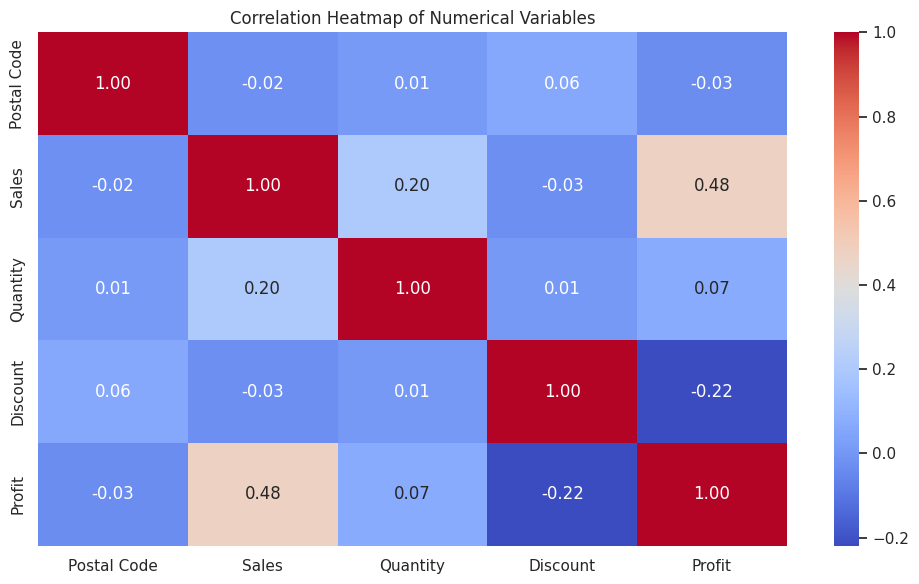

In [12]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr()

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

The heatmap shows the relationships between numerical columns in the dataset. Positive values indicate positive relationships, while negative values indicate negative relationships. Correlation does not necessarily mean causation.

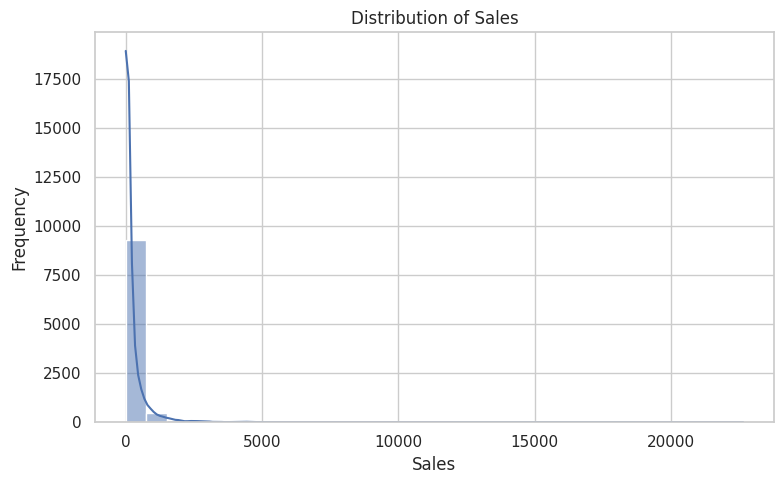

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Sales',
    bins=30,
    kde=True
)

plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

The histogram shows how sales values are distributed in the dataset. It helps us understand the spread of sales values and identify unusually high sales.

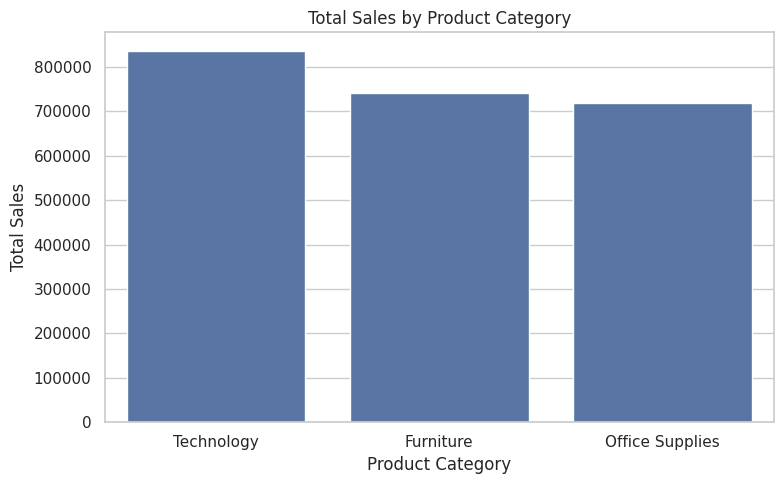

In [14]:
category_sales = (
    df.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

The bar chart compares total sales across different product categories. The category with the tallest bar has the highest total sales.

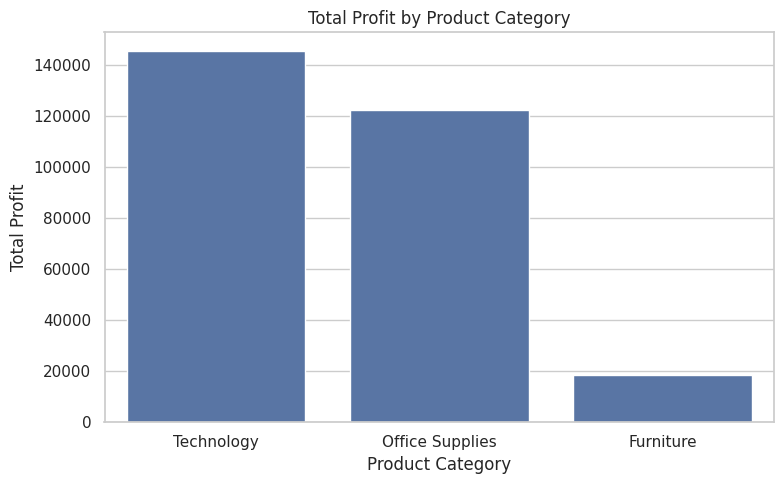

In [15]:
category_profit = (
    df.groupby('Category')['Profit']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title('Total Profit by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

The chart compares total profit across product categories. It helps identify which category generates the highest profit.

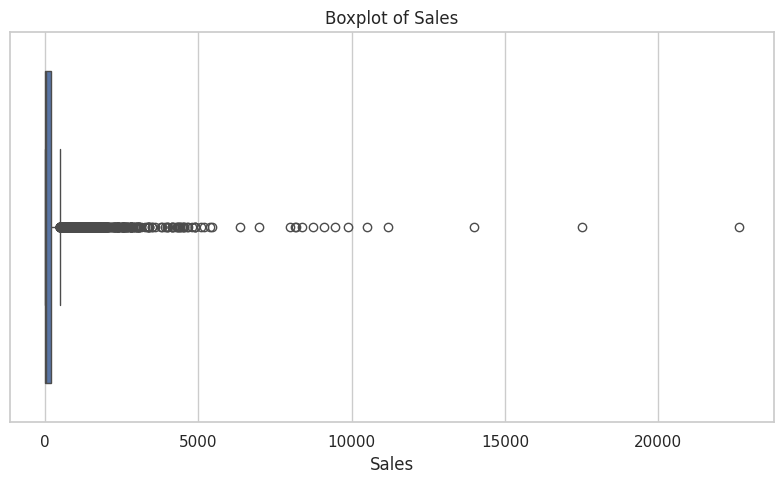

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Sales'
)

plt.title('Boxplot of Sales')
plt.xlabel('Sales')

plt.tight_layout()
plt.show()

The boxplot helps identify unusually high or low sales values. These values should be checked before deciding whether they are errors.

/tmp/ipykernel_2308/3670092334.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_analysis, x='Region', y='Sales', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_2308/3670092334.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=region_analysis, x='Region', y='Profit', ax=axes[1], palette='Greens_d')


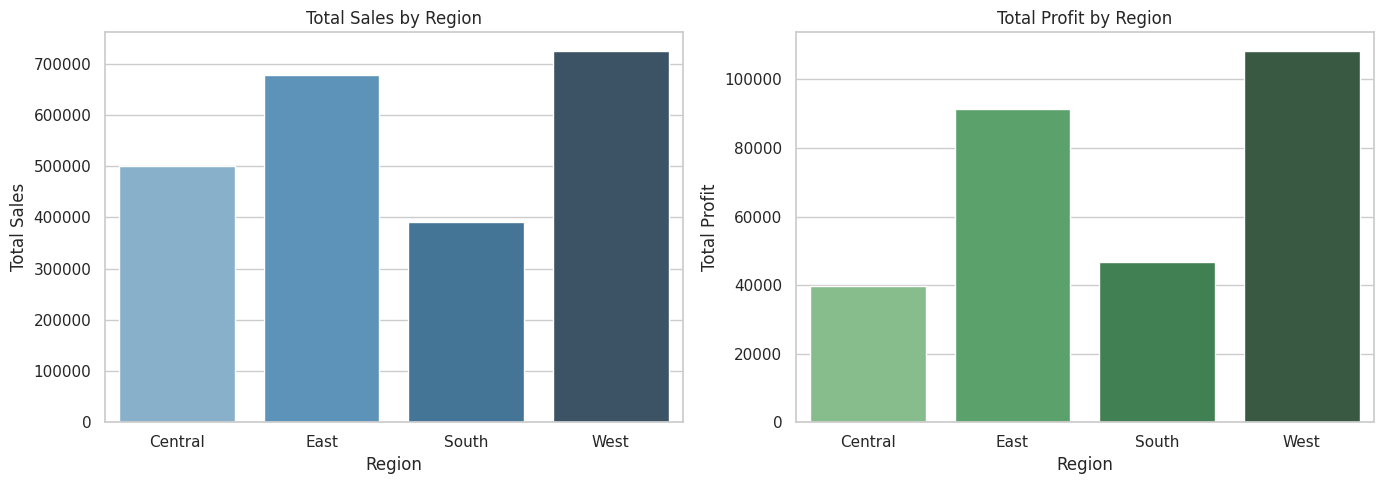

In [21]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    errors='coerce'
)

monthly_sales = (
    df.dropna(subset=['Order Date'])
      .set_index('Order Date')['Sales']
      .resample('MS')
      .sum()
)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

The line chart shows how total sales change from month to month. It helps identify months with higher and lower sales.
Repeat these steps for each graph. Make sure the observations match your actual results.

In [24]:
print("Category with highest sales:")
print(category_sales.idxmax())
print(category_sales.max())

print("\nCategory with highest profit:")
print(category_profit.idxmax())
print(category_profit.max())

print("\nMonth with highest sales:")
print(monthly_sales.idxmax())
print(monthly_sales.max())

Category with highest sales:
Technology
836154.033

Category with highest profit:
Technology
145454.9481

Region with highest sales:
West
725255.6365

Region with highest profit:
West
108329.8079


Top 3 Insights
1. Sales Performance
The sales analysis helps identify which product category generates the highest total sales. This information helps us understand which category contributes most to sales revenue.
2. Profitability Analysis
The profit analysis helps identify which product category generates the highest total profit. Comparing sales and profit helps us understand the profitability of different categories.
3. Monthly Sales Trend
The monthly sales analysis helps identify months with higher and lower sales. This information can help businesses understand changes in sales performance.
Step 4: Add your actual results
Look at your graphs and update the three insights with your findings.